# Daily Challenge — Pokémon Win Prediction Analysis

Use historical battles to calculate a win percentage per Pokémon, then predict that percentage from pre-battle attributes. Keep **Pokemon Data Analysis Tutorial.zip** in the notebook's working folder and run the cells in order. This notebook uses pandas, NumPy, Matplotlib, Seaborn, scikit-learn, and XGBoost.

In [1]:
# Step 1. Read the stats and labeled battles directly from the course ZIP.
from pathlib import Path
from zipfile import ZipFile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

with ZipFile("Pokemon Data Analysis Tutorial.zip") as archive:
    folder = "Pokemon Data Analysis Tutorial/"
    with archive.open(folder + "pokemon.csv") as csv:
        pokemon = pd.read_csv(csv).rename(columns={"#": "Pokemon_ID"})
    with archive.open(folder + "combats.csv") as csv:
        battles = pd.read_csv(csv)
print(f"Pokémon: {len(pokemon):,} | Labeled battles: {len(battles):,}")
print(pokemon.isna().sum().to_string())

# Step 2. Repair Primeape's missing name and mark single-type Pokémon.
pokemon.loc[pokemon["Pokemon_ID"].eq(62) & pokemon["Name"].isna(), "Name"] = "Primeape"
pokemon["Type 2"] = pokemon["Type 2"].fillna("None")

# Check that every winner participated and all IDs exist in the stats table.
first, second = battles["First_pokemon"], battles["Second_pokemon"]
winner = battles["Winner"]
assert pokemon["Pokemon_ID"].is_unique
assert (winner.eq(first) | winner.eq(second)).all()
assert first.isin(pokemon["Pokemon_ID"]).all() and second.isin(pokemon["Pokemon_ID"]).all()

Pokémon: 800 | Labeled battles: 50,000
Pokemon_ID      0
Name            1
Type 1          0
Type 2        386
HP              0
Attack          0
Defense         0
Sp. Atk         0
Sp. Def         0
Speed           0
Generation      0
Legendary       0


In [2]:
# Step 3. Count both participants once per battle and count just one winner.
# Repeated matchups represent separate observations and are retained.
appearances = pd.concat([first, second], ignore_index=True).value_counts().rename("Battles")
wins = winner.value_counts().rename("Wins")
outcomes = pd.concat([appearances, wins], axis=1).fillna(0).astype(int)
analysis = pokemon.merge(outcomes, how="left", left_on="Pokemon_ID",
                         right_index=True, validate="one_to_one")
analysis[["Battles", "Wins"]] = analysis[["Battles", "Wins"]].fillna(0).astype(int)
# Zero wins in played battles is a valid 0%. A Pokémon with no battles
# has an undefined target and stays in the cleaned table with a blank rate.
analysis["Win_Percentage"] = 100 * analysis["Wins"] / analysis["Battles"].replace(0, np.nan)
played = analysis.dropna(subset=["Win_Percentage"]).copy()
print(f"With battle history: {len(played)} | Without battle history: {len(analysis) - len(played)}")
print(analysis[["Pokemon_ID", "Name", "Battles", "Wins", "Win_Percentage"]].head().to_string(index=False))
analysis.to_csv("Pokemon Win Rates - Cleaned.csv", index=False)

With battle history: 784 | Without battle history: 16
 Pokemon_ID          Name  Battles  Wins  Win_Percentage
          1     Bulbasaur      133    37       27.819549
          2       Ivysaur      121    46       38.016529
          3      Venusaur      132    89       67.424242
          4 Mega Venusaur      125    70       56.000000
          5    Charmander      112    55       49.107143


Speed      0.938
Attack     0.503
Sp. Atk    0.481
Sp. Def    0.302
HP         0.262
Defense    0.115


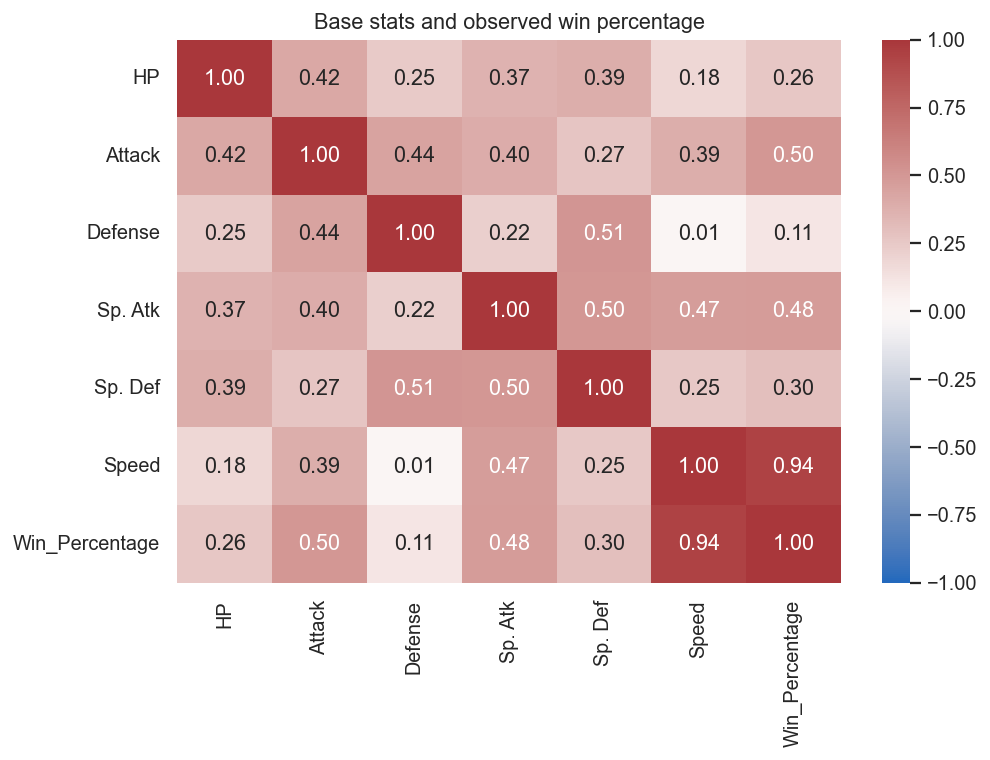

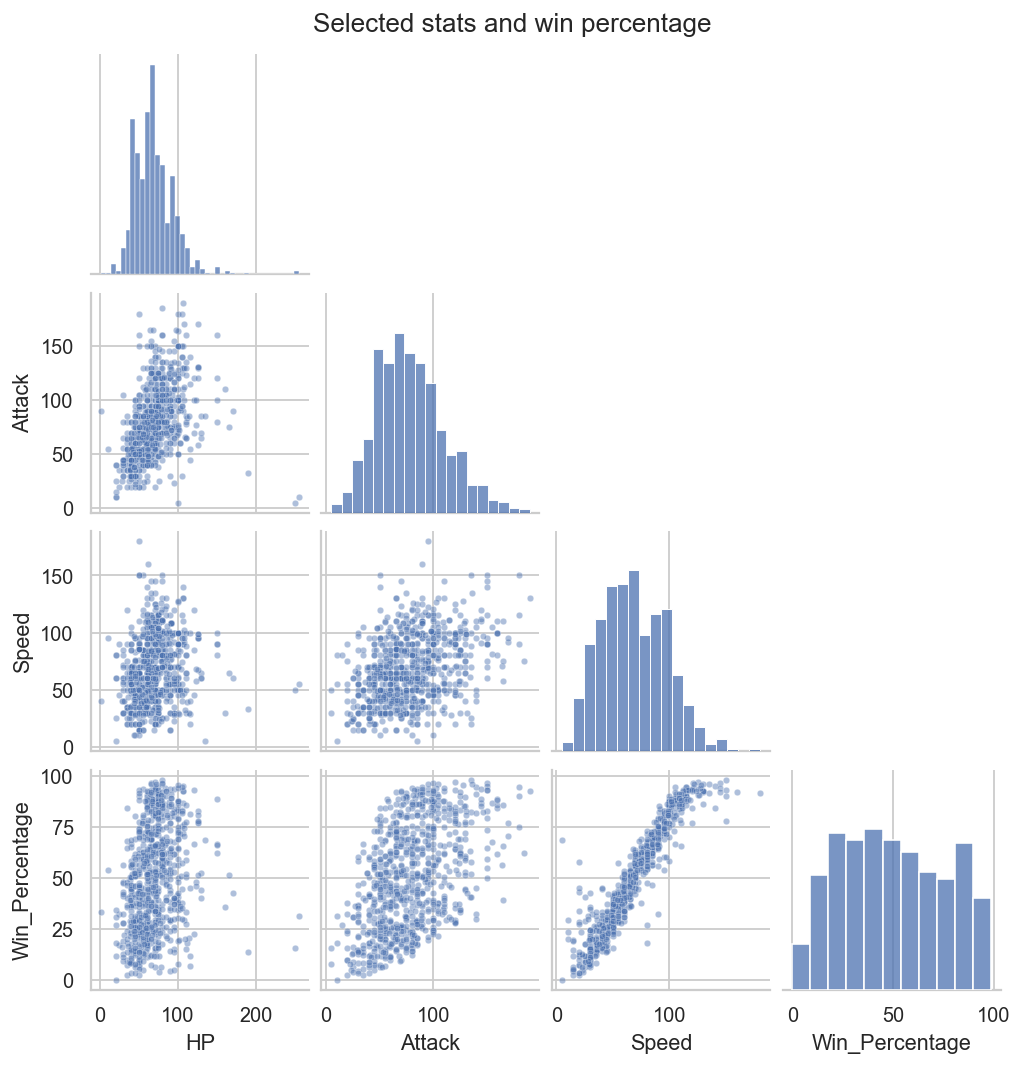

In [3]:
# Step 4. Compare stats with win percentage using Pearson correlations.
sns.set_theme(style="whitegrid")
stats = ["HP", "Attack", "Defense", "Sp. Atk", "Sp. Def", "Speed"]
target = "Win_Percentage"
corr = played[stats + [target]].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, ax=ax)
ax.set_title("Base stats and observed win percentage")
fig.tight_layout()
plt.show()
print(corr[target].drop(target).sort_values(key=abs, ascending=False).round(3).to_string())

# Use a corner pairplot to see distributions and relationships without
# repeating mirror-image scatter plots.
pair = sns.pairplot(played[["HP", "Attack", "Speed", target]], corner=True,
                    diag_kind="hist", height=2, plot_kws={"s": 13, "alpha": 0.45})
pair.fig.suptitle("Selected stats and win percentage", y=1.02)
plt.show()

In [4]:
# Step 5. Rank the top ten by unrounded rate. Use battle count and then ID
# to break ties, and show the denominator so the rankings have context.
top = played.sort_values([target, "Battles", "Pokemon_ID"],
                         ascending=[False, False, True]).head(10)
print(top[["Name", "Type 1", "Wins", "Battles", target, *stats]]
      .round({target: 2}).to_string(index=False))
print("Top ten average stats compared with all Pokémon with battle history:")
print(pd.DataFrame({"Top ten": top[stats].mean(), "All played": played[stats].mean()})
      .round(1).to_string())

                    Name  Type 1  Wins  Battles  Win_Percentage  HP  Attack  Defense  Sp. Atk  Sp. Def  Speed
         Mega Aerodactyl    Rock   127      129           98.45  80     135       85       70       95    150
                 Weavile    Dark   116      119           97.48  70     120       65       45       85    125
  Tornadus Therian Forme  Flying   121      125           96.80  79     100       80      110       90    121
           Mega Beedrill     Bug   115      119           96.64  65     150       40       15       80    145
              Aerodactyl    Rock   136      141           96.45  80     105       65       60       75    130
            Mega Lopunny  Normal   124      129           96.12  65     136       94       54       96    135
                Greninja   Water   122      127           96.06  72      95       67      103       71    122
Meloetta Pirouette Forme  Normal   118      123           95.93 100     128       90       77       77    128
          

In [5]:
# Step 6. Hold out 20% of Pokémon. Use only attributes known before battle.
# Exclude wins, battles, win percentage, name and ID from predictors.
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBRegressor

numeric = stats + ["Generation"]
categories = ["Type 1", "Type 2", "Legendary"]
X = played[numeric + categories]
y = played[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training: {len(y_train)} | Test: {len(y_test)}")

# Fit encoders and imputers only on training rows. Scale numeric inputs
# for the linear model. The tree models can use the original units.
def preprocessing(scale=False):
    numeric_steps = [SimpleImputer(strategy="median")]
    if scale:
        numeric_steps.append(StandardScaler())
    return ColumnTransformer([
        ("numeric", make_pipeline(*numeric_steps), numeric),
        ("categories", make_pipeline(SimpleImputer(strategy="most_frequent"),
                                    OneHotEncoder(handle_unknown="ignore", sparse_output=False)), categories),
    ])

models = {
    "Median baseline": DummyRegressor(strategy="median"),
    "Linear regression": make_pipeline(preprocessing(scale=True), LinearRegression()),
    "Random forest": make_pipeline(preprocessing(), RandomForestRegressor(
        n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=1)),
    "XGBoost": make_pipeline(preprocessing(), XGBRegressor(
        n_estimators=250, learning_rate=0.05, max_depth=3, subsample=0.85,
        objective="reg:squarederror", random_state=42, n_jobs=1)),
}

Training: 627 | Test: 157


XGBoost               3.733
Random forest         4.285
Linear regression     5.548
Median baseline      22.559


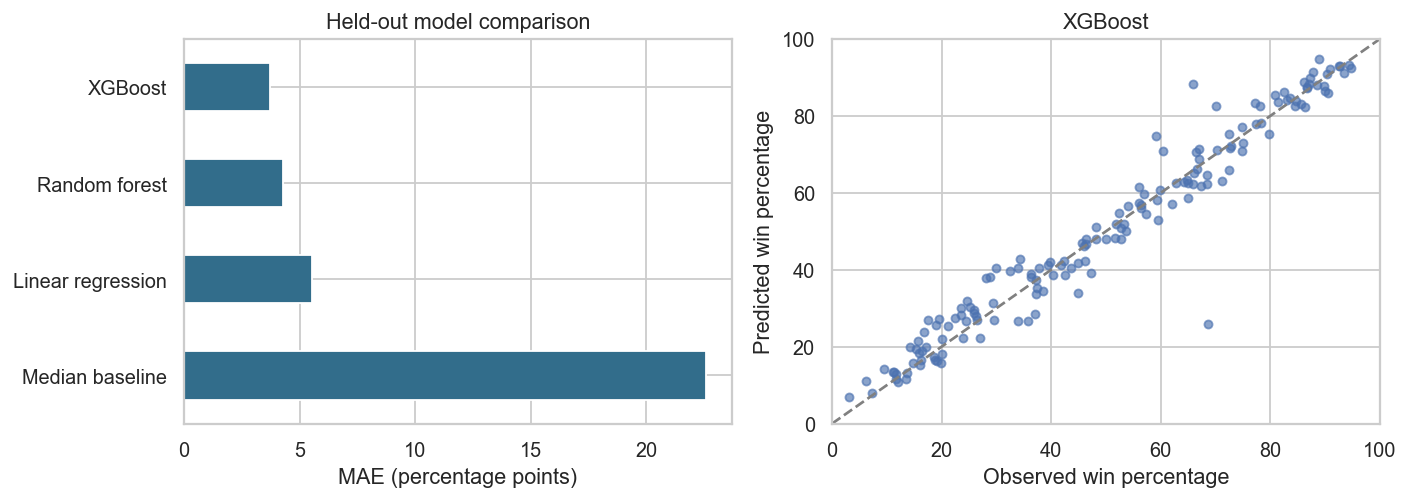

In [6]:
# Step 7. Use the same held-out Pokémon for each model. Keep predictions
# within 0–100% and report MAE in percentage points.
predictions = {}
errors = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    prediction = np.clip(model.predict(X_test), 0, 100)
    predictions[name] = prediction
    errors[name] = mean_absolute_error(y_test, prediction)
scores = pd.Series(errors, name="Test MAE (percentage points)").sort_values()
best = scores.drop("Median baseline").idxmin()
print(scores.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
scores.sort_values(ascending=False).plot.barh(ax=axes[0], color="#326d8b")
axes[0].set(xlabel="MAE (percentage points)", title="Held-out model comparison")
axes[1].scatter(y_test, predictions[best], alpha=0.65, s=20)
axes[1].plot([0, 100], [0, 100], "--", color="gray")
axes[1].set(xlabel="Observed win percentage", ylabel="Predicted win percentage",
            title=best, xlim=(0, 100), ylim=(0, 100))
fig.tight_layout()
plt.show()

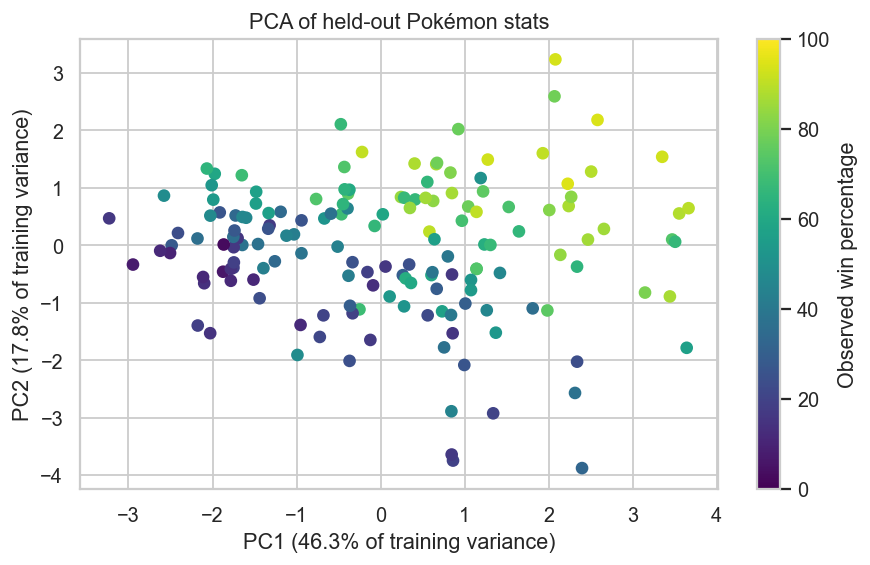

In [7]:
# Step 8. Use PCA to visualize the six base stats in two dimensions.
# Fit the scaler and PCA on the training stats, then project test rows.
from sklearn.decomposition import PCA

projector = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), PCA(n_components=2))
projector.fit(X_train[stats])
xy = projector.transform(X_test[stats])
variance = projector.named_steps["pca"].explained_variance_ratio_
fig, ax = plt.subplots(figsize=(7, 4.5))
points = ax.scatter(xy[:, 0], xy[:, 1], c=y_test, cmap="viridis", vmin=0, vmax=100)
fig.colorbar(points, ax=ax, label="Observed win percentage")
ax.set(xlabel=f"PC1 ({variance[0]:.1%} of training variance)",
       ylabel=f"PC2 ({variance[1]:.1%} of training variance)", title="PCA of held-out Pokémon stats")
fig.tight_layout()
plt.show()

## Findings

**Mega Aerodactyl** led the observed ranking at **98.45%** over 129 battles. The top ten averaged **130.1 Speed**, compared with **68.4** across all Pokémon with battle history. Speed's correlation with win percentage was **0.938**. This is an association in the recorded matchups.

**XGBoost** had the lowest held-out MAE of the three regressors at **3.73 percentage points**, versus **22.56** for the median baseline. The test split keeps each Pokémon in one partition, but opponents can appear in both partitions and the historical rates can reflect differences in opponent mix. The model estimates an aggregate win percentage. A head-to-head prediction would require attributes of both participants.